# JC Citi Bike 需求预测：数据探索
本 Notebook 是近期 JC 主线。目标为 JC 发布服务范围内每小时出发次数；时间轴使用 UTC，日历特征使用 America/New_York。
最终测试年份 2025 不用于本 Notebook 的特征选择或结论设计。

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
from src.jc_weather import FIELDS, load_or_fetch_weather, join_hourly
data_path = ROOT / 'data/processed/jc_hourly_2024_2025.csv'
df = pd.read_csv(data_path, parse_dates=['timestamp_utc', 'local_time'], index_col='timestamp_utc')
df.index = pd.DatetimeIndex(df.index, tz='UTC')
config = json.loads((ROOT / 'configs/jc_experiment.json').read_text(encoding='utf-8'))
dev = df.loc[df.index < pd.Timestamp(config['final_fit_end_utc'])].copy()
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Noto Sans CJK SC', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
print('rows:', len(df), 'scorable development rows:', dev['departures'].notna().sum())
display(dev.head())

rows: 17544 scorable development rows: 8777


,departures,local_time,dst_ambiguous_target,hour,weekday,month,is_weekend,hour_sin,hour_cos,weekday_sin,weekday_cos
timestamp_utc,,,,,,,,,,,
2024-01-01 05:00:00+00:00,69.0,2024-01-01 00:00:00,False,0,0,1,False,0.000000,1.000000,0.0,1.0
2024-01-01 06:00:00+00:00,72.0,2024-01-01 01:00:00,False,1,0,1,False,0.258819,0.965926,0.0,1.0
2024-01-01 07:00:00+00:00,95.0,2024-01-01 02:00:00,False,2,0,1,False,0.500000,0.866025,0.0,1.0
2024-01-01 08:00:00+00:00,41.0,2024-01-01 03:00:00,False,3,0,1,False,0.707107,0.707107,0.0,1.0
2024-01-01 09:00:00+00:00,16.0,2024-01-01 04:00:00,False,4,0,1,False,0.866025,0.500000,0.0,1.0


## 数据质量与目标分布
重复 ride_id 和 DST 处理见 `results/metrics/jc_preparation_audit.json`。目标为观测出发次数，不声称等同于未受车辆供应限制的潜在需求。

In [2]:
audit = json.loads((ROOT / 'results/metrics/jc_preparation_audit.json').read_text(encoding='utf-8'))
display({k: audit[k] for k in ['raw_rows','unique_ids_after_exclusions','conflicting_ids_excluded','ambiguous_dst_ride_rows_excluded','ambiguous_dst_target_hours_unscorable','scorable_target_hours','zero_departure_hours']})
display(dev['departures'].describe())

{'raw_rows': 2055155,
 'unique_ids_after_exclusions': 2055121,
 'conflicting_ids_excluded': 10,
 'ambiguous_dst_ride_rows_excluded': 151,
 'ambiguous_dst_target_hours_unscorable': 4,
 'scorable_target_hours': 17540,
 'zero_departure_hours': 74}

count    8777.000000
mean      119.879686
std       104.384125
min         0.000000
25%        31.000000
50%       100.000000
75%       177.000000
max       552.000000
Name: departures, dtype: float64

C:\Users\nahida\AppData\Local\Temp\ipykernel_45568\1943573746.py:8: UserWarning: Glyph 23567 (\N{CJK UNIFIED IDEOGRAPH-5C0F}) missing from current font.
  fig.tight_layout()
C:\Users\nahida\AppData\Local\Temp\ipykernel_45568\1943573746.py:8: UserWarning: Glyph 26102 (\N{CJK UNIFIED IDEOGRAPH-65F6}) missing from current font.
  fig.tight_layout()
C:\Users\nahida\AppData\Local\Temp\ipykernel_45568\1943573746.py:8: UserWarning: Glyph 20986 (\N{CJK UNIFIED IDEOGRAPH-51FA}) missing from current font.
  fig.tight_layout()
C:\Users\nahida\AppData\Local\Temp\ipykernel_45568\1943573746.py:8: UserWarning: Glyph 21457 (\N{CJK UNIFIED IDEOGRAPH-53D1}) missing from current font.
  fig.tight_layout()
C:\Users\nahida\AppData\Local\Temp\ipykernel_45568\1943573746.py:8: UserWarning: Glyph 37327 (\N{CJK UNIFIED IDEOGRAPH-91CF}) missing from current font.
  fig.tight_layout()
C:\Users\nahida\AppData\Local\Temp\ipykernel_45568\1943573746.py:8: UserWarning: Glyph 20998 (\N{CJK UNIFIED IDEOGRAPH-5206}) miss

D:\P Miniconda3.13\envs\d2l\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 23567 (\N{CJK UNIFIED IDEOGRAPH-5C0F}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
D:\P Miniconda3.13\envs\d2l\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 26102 (\N{CJK UNIFIED IDEOGRAPH-65F6}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
D:\P Miniconda3.13\envs\d2l\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 20986 (\N{CJK UNIFIED IDEOGRAPH-51FA}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
D:\P Miniconda3.13\envs\d2l\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 21457 (\N{CJK UNIFIED IDEOGRAPH-53D1}) missing from current font.
  fig.canvas.print_figure(bytes_io, **kw)
D:\P Miniconda3.13\envs\d2l\lib\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 37327 (\N{CJK UNIFIED IDEOGRAPH-91CF}) missing from current font.
  fig.canvas.prin

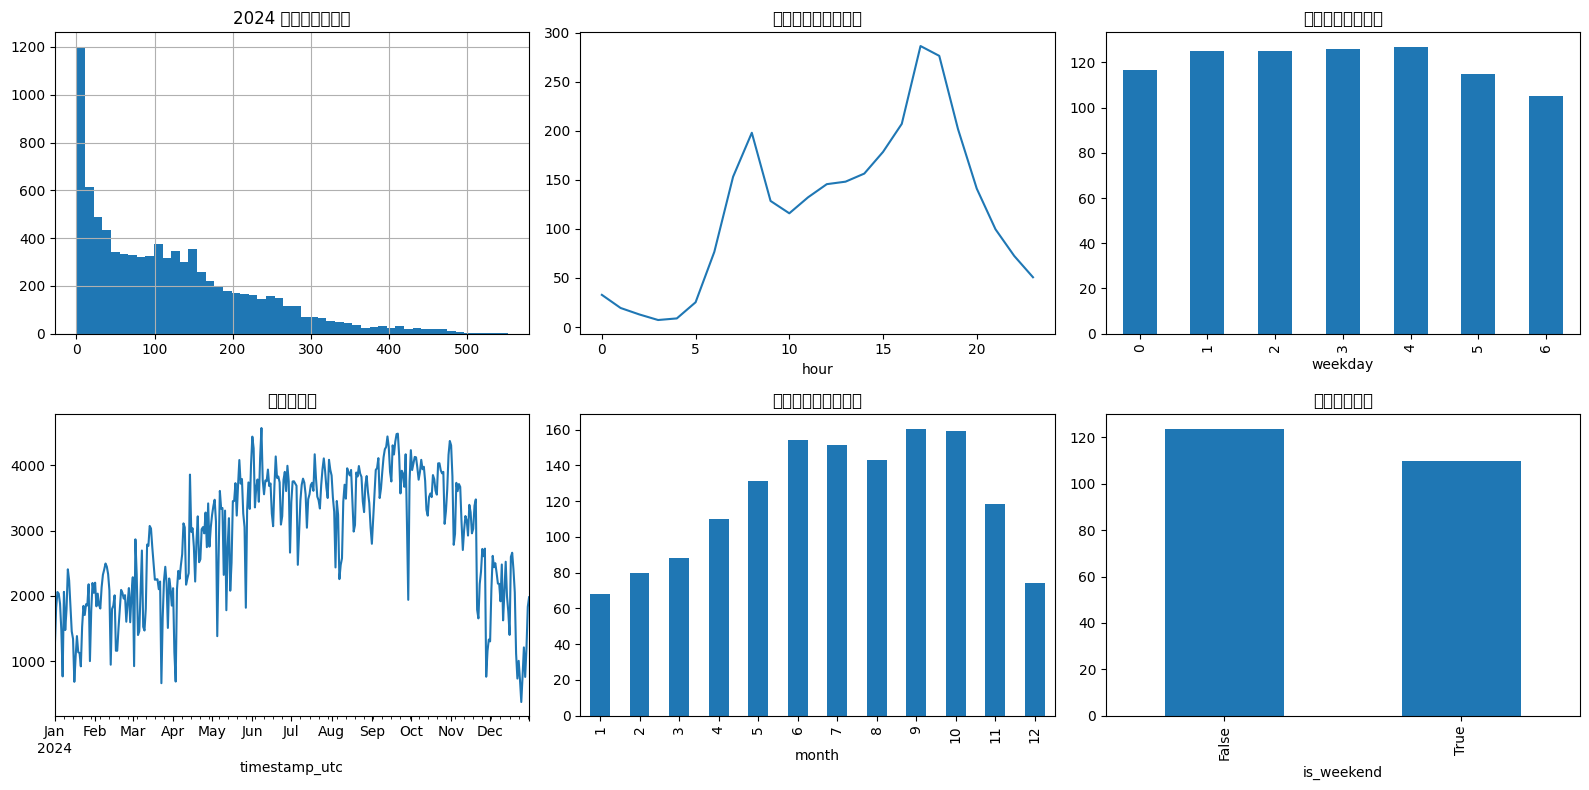

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
dev['departures'].hist(bins=50, ax=axes[0, 0]); axes[0, 0].set_title('2024 小时出发量分布')
dev.groupby('hour')['departures'].mean().plot(ax=axes[0, 1]); axes[0, 1].set_title('本地小时平均出发量')
dev.groupby('weekday')['departures'].mean().plot.bar(ax=axes[0, 2]); axes[0, 2].set_title('星期几平均出发量')
dev.resample('D')['departures'].sum(min_count=1).plot(ax=axes[1, 0]); axes[1, 0].set_title('每日出发量')
dev.groupby('month')['departures'].mean().plot.bar(ax=axes[1, 1]); axes[1, 1].set_title('月份平均小时出发量')
dev.groupby('is_weekend')['departures'].mean().plot.bar(ax=axes[1, 2]); axes[1, 2].set_title('周末与工作日')
fig.tight_layout()
figures = ROOT / 'results/figures'; figures.mkdir(parents=True, exist_ok=True)
fig.savefig(figures / 'jc_eda_2024.png', dpi=150, bbox_inches='tight')
plt.show()

## 天气连接试验
天气数据先使用 Open-Meteo 历史接口的 UTC 小时响应。这里仅验证 API 连接与覆盖，不将历史再分析值解释为当时已经可用的预报。
正式建模前还需缓存全年天气、记录请求元数据和许可归属。

In [4]:
weather, weather_meta = load_or_fetch_weather('2024-01-01', '2025-01-01', 'jc_weather_2024_utc')
joined = join_hourly(dev, weather)
print('weather rows:', len(weather), 'joined rows:', len(joined))
display(joined[FIELDS].isna().sum())
display(weather_meta)

weather rows: 8784 joined rows: 8779


temperature_2m          0
relative_humidity_2m    0
precipitation           0
wind_speed_10m          0
dtype: int64

{'request': {'latitude': 40.73,
  'longitude': -74.04,
  'start_date': '2024-01-01',
  'end_date': '2024-12-31',
  'hourly': 'temperature_2m,relative_humidity_2m,precipitation,wind_speed_10m',
  'timezone': 'UTC'},
 'resolved_latitude': 40.738136,
 'resolved_longitude': -74.04254,
 'hourly_units': {'time': 'iso8601',
  'temperature_2m': '°C',
  'relative_humidity_2m': '%',
  'precipitation': 'mm',
  'wind_speed_10m': 'km/h'}}

## 下一步
下一阶段将固定历史滞后特征、天气历史特征和防泄漏的下一小时目标，然后实现朴素基准、线性回归与随机森林。模型实验不在本 Notebook 中隐式改变切分配置。